# 05 V8 — Feature-Tokenized CNN + SE + Multi-Head Attention

**CIC-IDS2017 • 60 feature • 15 classes • Kaggle GPU**

**Mục tiêu:** kiểm tra xem feature tokenization, multi-scale CNN, Squeeze-and-Excitation (SE) và global self-attention có cải thiện **validation Macro-F1**, đặc biệt XSS/Brute Force, hay không. Thí nghiệm ablation thay **từng thành phần** trong kiến trúc.

**Giao thức:** dùng **chính xác** `cic_expanded_splits.parquet` và `feature_sets.json` do Notebook 03B xuất, giống Notebook 04 V2 / Notebook 05 V6. Không chia lại; preprocessing fit trên train; chọn checkpoint, mô hình, ngưỡng hoàn toàn trên validation; test dùng một lần cuối sau khi khóa lựa chọn. Không tuyên bố cải thiện so với V6 bằng việc so lại nhiều lần trên test đã xem.

**Cảnh báo khoa học:** token dùng embedding feature học được, không phải temporal token; CNN ở đây trượt trên **thứ tự feature cố định**, vốn không nhất thiết có quan hệ lân cận tự nhiên. SE ở đây điều chỉnh kênh embedding; attention học tương tác giữa các feature. SQL Injection/Heartbleed quá hiếm để rút ra kết luận mạnh. Không dùng IP/timestamp không tồn tại trong CSV.

## 1. Cấu hình, thiết bị và output

In [17]:
from pathlib import Path
import json, time, random, hashlib, gc, shutil
from dataclasses import dataclass, asdict
import numpy as np
import pandas as pd
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
import joblib
from IPython.display import display
import matplotlib.pyplot as plt

SEARCH_MODE = 'balanced'  # 'smoke': quick sanity; 'balanced': research default; 'full': extra search
INPUT_DIR = None          # explicit folder containing 03B artifacts if auto-discovery is ambiguous
OUTPUT = Path('/kaggle/working/nids_outputs/05_CNN_Ablation_V8_Tokenized') if Path('/kaggle/working').exists() else Path('reports/05_CNN_Ablation_V8_Tokenized')
OUTPUT.mkdir(parents=True, exist_ok=True)
SEED=42
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BUDGET={
 'smoke':   dict(epochs=2, patience=2, search=False, seeds=[42], batch=256),
 'balanced':dict(epochs=55,patience=10,search=True, seeds=[42,43,44],batch=256),
 'full':    dict(epochs=90,patience=15,search=True, seeds=[42,43,44,45,46],batch=256),
}[SEARCH_MODE]
def seed_everything(seed):
 random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
 if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
seed_everything(SEED)
print('DEVICE', DEVICE, 'GPU',torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else 'CPU', 'BUDGET', BUDGET)

DEVICE cuda GPU Tesla T4 BUDGET {'epochs': 55, 'patience': 10, 'search': True, 'seeds': [42, 43, 44], 'batch': 256}


## 2. Đọc đúng output 03B; xác minh schema và split

In [18]:
needed=['cic_expanded_splits.parquet','feature_sets.json','experiment_manifest.json']
if INPUT_DIR is not None:
 candidates=[Path(INPUT_DIR)]
else:
 candidates=[]
 local=Path('/kaggle/working/nids_outputs/03B_CIC_Feature_Engineering')
 if local.is_dir():candidates.append(local)
 if Path('/kaggle/input').exists():
  candidates += [f.parent for f in Path('/kaggle/input').rglob(needed[0])]
valid=sorted({str(p.resolve()) for p in candidates if all((p/f).is_file() for f in needed)})
if len(valid)!=1:
 raise FileNotFoundError(f'Expected ONE complete Notebook 03B output; found {valid}. Add Input output 03B or set INPUT_DIR.')
input_dir=Path(valid[0]);split_path=input_dir/needed[0]
manifest=json.loads((input_dir/'experiment_manifest.json').read_text(encoding='utf8'))
feature_sets=json.loads((input_dir/'feature_sets.json').read_text(encoding='utf8'))
feature_variant=manifest['validation_selected_feature_set']
features=list(feature_sets[feature_variant]);N_FEATURES=len(features)
df=pd.read_parquet(split_path)
required={'Label','_binary_label','_split','_source_file','_source_row','_duplicate_group'}
assert required.issubset(df.columns),f'Missing columns: {required-set(df.columns)}'
assert len(df)==int(manifest['sample_rows'])
assert set(df['_split'].astype(str))=={'train','val','test'}
assert len(features)==len(set(features)) and set(features).issubset(df.columns)
assert all(not f.startswith('_') and f!='Label' for f in features)
assert df.groupby('_duplicate_group')['_split'].nunique().max()==1,'Exact duplicate group leaked across splits'
assert not df.duplicated(['_source_file','_source_row']).any(),'Duplicate source row'
labels=df['Label'].astype(str)
assert np.array_equal(df['_binary_label'].astype(int).to_numpy(),labels.ne('BENIGN').astype(int).to_numpy())
mask={p:df['_split'].eq(p).to_numpy() for p in ['train','val','test']}
enc=LabelEncoder().fit(labels.loc[mask['train']])
assert set(enc.classes_)==set(labels),'A class is absent from train'
y={p:enc.transform(labels.loc[m]).astype(np.int64) for p,m in mask.items()}
classes=enc.classes_.tolist();K=len(classes);benign_idx=int(enc.transform(['BENIGN'])[0]);all_ids=np.arange(K)
raw=df[features].apply(pd.to_numeric,errors='coerce').replace([np.inf,-np.inf],np.nan).astype('float32')
sha=hashlib.sha256(split_path.read_bytes()).hexdigest()
print('INPUT:',split_path,'SHA256:',sha)
print('FEATURE SET:',feature_variant,'N_FEATURES:',N_FEATURES,'CLASSES:',K)
print('SPLIT:',{p:int(m.sum()) for p,m in mask.items()})
print(pd.crosstab(labels,df['_split']).to_string())
assert N_FEATURES==60 and K==15, 'This experiment expects the same 60-feature/15-class protocol as 04 V2'
(OUTPUT/'feature_names.json').write_text(json.dumps(features,ensure_ascii=False,indent=2),encoding='utf8')

INPUT: /kaggle/input/datasets/chienvoo/nids-outputs/nids_outputs_backup/nids_outputs/03B_CIC_Feature_Engineering/cic_expanded_splits.parquet SHA256: d6d516853f1de28ac8614495bfa37f5bbcc52a0dfedb3caafdfb15415578d152
FEATURE SET: with_port N_FEATURES: 60 CLASSES: 15
SPLIT: {'train': 23922, 'val': 7862, 'test': 7409}
_split                        test  train   val
Label                                          
BENIGN                        1353   4279  1368
Bot                            387   1190   389
DDoS                           681   2107   712
DoS GoldenEye                  681   2096   723
DoS Hulk                       585   2136   779
DoS Slowhttptest               627   2186   687
DoS slowloris                  699   2077   724
FTP-Patator                    558   2259   683
Heartbleed                       2      8     1
Infiltration                     8     21     7
PortScan                       717   2102   681
SSH-Patator                    681   2112   707
Web Attack ï¿

1283

## 3. Train-only imputation và scaling
Không loại bỏ test rows, không oversample validation/test. Với mỗi fold, học median/scaler **chỉ train**. Lưu preprocessing để deploy được.

In [19]:
imputer=SimpleImputer(strategy='median',keep_empty_features=True)
scaler=StandardScaler()
train_imp=imputer.fit_transform(raw.loc[mask['train']])
X={'train':scaler.fit_transform(train_imp).astype(np.float32)}
for p in ['val','test']:
 X[p]=scaler.transform(imputer.transform(raw.loc[mask[p]])).astype(np.float32)
for p in X:
 assert X[p].shape==(len(y[p]),N_FEATURES) and np.isfinite(X[p]).all()
train_counts=np.bincount(y['train'],minlength=K)
print('Train count min / max:',train_counts.min(),train_counts.max())
print('No preprocessing fit on val/test.')
joblib.dump({'imputer':imputer,'scaler':scaler,'label_encoder':enc,'features':features,
 'feature_variant':feature_variant,'split_sha256':sha},OUTPUT/'preprocessing.joblib')

Train count min / max: 8 4279
No preprocessing fit on val/test.


['/kaggle/working/nids_outputs/05_CNN_Ablation_V8_Tokenized/preprocessing.joblib']

## 4. Mô hình — Feature Tokenization + Multi-Scale CNN + SE + MHSA

Mỗi feature số `x_i` được nhúng thành token riêng: `t_i = x_i W_i + b_i`, trong đó `W_i, b_i ∈ R^d` là tham số **riêng của feature i**. Tensor `[B, 60, d]` đi qua `Conv1D` (theo feature position) và SE. `nn.MultiheadAttention` học quan hệ **toàn cục giữa feature tokens**, không phải temporal attention.

**Ablation công bằng:**
- T0: Feature Tokenizer → residual token MLP / mean pooling (không CNN, SE, MHSA).
- T1: Tokenizer → multi-scale CNN (không SE, MHSA).
- T2: Tokenizer → CNN → SE (không MHSA).
- T3: Tokenizer → CNN → MHSA (không SE).
- T4: Tokenizer → CNN → SE → MHSA (đề xuất).
- T5: T4 + nhánh residual MLP của 60 feature gốc (mở rộng, báo riêng).

`T0–T4` dùng cùng chiều rộng và head; không giả định tham số tuyệt đối bằng nhau — báo cáo param count.

In [20]:
class FeatureTokenizer(nn.Module):
 def __init__(self,n_features,d_model):
  super().__init__()
  self.weight=nn.Parameter(torch.empty(n_features,d_model))
  self.bias=nn.Parameter(torch.empty(n_features,d_model))
  nn.init.normal_(self.weight,mean=0.,std=.02)
  nn.init.normal_(self.bias,mean=0.,std=.02)
 def forward(self,x):
  return x.unsqueeze(-1)*self.weight.unsqueeze(0)+self.bias.unsqueeze(0)

class SEChannels(nn.Module):
 def __init__(self,d_model,reduction=8):
  super().__init__()
  hidden=max(8,d_model//reduction)
  self.net=nn.Sequential(nn.Linear(d_model,hidden),nn.GELU(),nn.Linear(hidden,d_model),nn.Sigmoid())
 def forward(self,z):
  # z: B,F,D ; squeeze over feature-token positions
  return z * self.net(z.mean(dim=1)).unsqueeze(1)

class TokenResBlock(nn.Module):
 def __init__(self,d_model,dropout):
  super().__init__()
  self.norm=nn.LayerNorm(d_model)
  self.net=nn.Sequential(nn.Linear(d_model,2*d_model),nn.GELU(),nn.Dropout(dropout),nn.Linear(2*d_model,d_model))
  self.dropout=nn.Dropout(dropout)
 def forward(self,x):return x+self.dropout(self.net(self.norm(x)))

class TokenizedCNNSEAttention(nn.Module):
 def __init__(self,n_features,n_classes,d_model=64,heads=4,dropout=.15,
              use_cnn=True,use_se=True,use_attn=True,use_raw=False):
  super().__init__()
  assert d_model%heads==0
  self.flags={'use_cnn':use_cnn,'use_se':use_se,'use_attn':use_attn,'use_raw':use_raw}
  self.tokenizer=FeatureTokenizer(n_features,d_model)
  self.norm0=nn.Identity()  # preserve scalar feature magnitude before feature mixing
  if use_cnn:
   self.convs=nn.ModuleList([nn.Conv1d(d_model,d_model,k,padding=k//2) for k in (1,3,5)])
   self.conv_fuse=nn.Sequential(nn.Conv1d(3*d_model,d_model,1),nn.GELU())
   self.norm_cnn=nn.LayerNorm(d_model)
  self.se=SEChannels(d_model) if use_se else nn.Identity()
  if use_attn:
   self.attn_norm=nn.LayerNorm(d_model)
   self.mha=nn.MultiheadAttention(d_model,heads,dropout=dropout,batch_first=True)
   self.attn_dropout=nn.Dropout(dropout)
  self.token_mlp=TokenResBlock(d_model,dropout)
  self.pool_gate=nn.Linear(d_model,1)
  rep_dim=3*d_model
  if use_raw:
   self.raw_mlp=nn.Sequential(nn.Linear(n_features,2*d_model),nn.LayerNorm(2*d_model),nn.GELU(),
                              nn.Dropout(dropout),nn.Linear(2*d_model,d_model),nn.GELU())
   rep_dim+=d_model
  self.classifier=nn.Sequential(nn.LayerNorm(rep_dim),nn.Linear(rep_dim,2*d_model),nn.GELU(),
                                nn.Dropout(dropout),nn.Linear(2*d_model,n_classes))
 def forward(self,x):
  z=self.norm0(self.tokenizer(x))
  if self.flags['use_cnn']:
   q=z.transpose(1,2)
   mixed=self.conv_fuse(torch.cat([conv(q) for conv in self.convs],dim=1)).transpose(1,2)
   z=self.norm_cnn(z+mixed)
  z=self.se(z)
  if self.flags['use_attn']:
   q=self.attn_norm(z)
   z=z+self.attn_dropout(self.mha(q,q,q,need_weights=False)[0])
  z=self.token_mlp(z)
  weights=torch.softmax(self.pool_gate(z).squeeze(-1),dim=1)
  attentive=(z*weights.unsqueeze(-1)).sum(dim=1)
  reps=[attentive,z.mean(dim=1),z.amax(dim=1)]
  if self.flags['use_raw']:reps.append(self.raw_mlp(x))
  return self.classifier(torch.cat(reps,dim=1))

ARCHS={
 'T0_TokenOnly': dict(use_cnn=False,use_se=False,use_attn=False,use_raw=False),
 'T1_TokenCNN': dict(use_cnn=True,use_se=False,use_attn=False,use_raw=False),
 'T2_TokenCNN_SE': dict(use_cnn=True,use_se=True,use_attn=False,use_raw=False),
 'T3_TokenCNN_MHSA': dict(use_cnn=True,use_se=False,use_attn=True,use_raw=False),
 'T4_TokenCNN_SE_MHSA': dict(use_cnn=True,use_se=True,use_attn=True,use_raw=False),
 'T5_TokenCNN_SE_MHSA_Raw': dict(use_cnn=True,use_se=True,use_attn=True,use_raw=True),
}
def make_model(arch,d_model=64,dropout=.15,heads=4):
 return TokenizedCNNSEAttention(N_FEATURES,K,d_model=d_model,dropout=dropout,heads=heads,**ARCHS[arch])
for name in ARCHS:
 m=make_model(name).to(DEVICE)
 xx=torch.randn(3,N_FEATURES,device=DEVICE)
 assert m(xx).shape==(3,K)
 m(xx).sum().backward()
 assert all(p.grad is not None for p in m.parameters() if p.requires_grad)
 print(name,sum(p.numel() for p in m.parameters()),'params; forward/backward OK')
 del m
if DEVICE.type=='cuda':torch.cuda.empty_cache()

T0_TokenOnly 51472 params; forward/backward OK
T1_TokenCNN 101008 params; forward/backward OK
T2_TokenCNN_SE 102104 params; forward/backward OK
T3_TokenCNN_MHSA 117776 params; forward/backward OK
T4_TokenCNN_SE_MHSA 118872 params; forward/backward OK
T5_TokenCNN_SE_MHSA_Raw 143512 params; forward/backward OK


## 5. Train/validation loop và lưu checkpoint

Validation dùng **15-class Macro-F1**. Cross-entropy class weights được học từ train; không sử dụng nhãn val để fit loss. `balanced/full` huấn luyện trên GPU và lưu `best.pt`, `last.pt`, `history.csv` cho mỗi trial. Search không đọc test.

In [21]:
@dataclass(frozen=True)
class Config:
 arch:str
 seed:int=42
 d_model:int=64
 heads:int=4
 dropout:float=.15
 lr:float=.001
 weight_decay:float=.0001
 weight_power:float=.25
 batch_size:int=256

def build_class_weights(power):
 if power==0:return torch.ones(K,device=DEVICE)
 w=(train_counts.sum()/(K*np.maximum(train_counts,1)))**power
 w=np.clip(w,.35,8.);w=w/w.mean()
 return torch.tensor(w,dtype=torch.float32,device=DEVICE)

def loader_for(part,batch,seed):
 ds=TensorDataset(torch.from_numpy(X[part]),torch.from_numpy(y[part]))
 return DataLoader(ds,batch_size=batch,shuffle=(part=='train'),num_workers=0,
                   pin_memory=(DEVICE.type=='cuda'),generator=torch.Generator().manual_seed(seed))

@torch.inference_mode()
def logits_for(model,part,batch=1024):
 model.eval();arr=[]
 for xb,_ in loader_for(part,batch,SEED):
  arr.append(model(xb.to(DEVICE,non_blocking=True)).float().cpu().numpy())
 return np.concatenate(arr,axis=0)

def performance(truth,pred):
 is_attack=(np.asarray(truth)!=benign_idx);is_pred_attack=(np.asarray(pred)!=benign_idx)
 tn=int((~is_attack & ~is_pred_attack).sum());fp=int((~is_attack & is_pred_attack).sum())
 return dict(accuracy=float(accuracy_score(truth,pred)),
             macro_f1=float(f1_score(truth,pred,labels=all_ids,average='macro',zero_division=0)),
             weighted_f1=float(f1_score(truth,pred,labels=all_ids,average='weighted',zero_division=0)),
             attack_recall=float(recall_score(is_attack,is_pred_attack,zero_division=0)),
             fpr=float(fp/(tn+fp)) if tn+fp else None)

def run_trial(cfg,trial_id):
 seed_everything(cfg.seed)
 net=make_model(cfg.arch,cfg.d_model,cfg.dropout,cfg.heads).to(DEVICE)
 opt=torch.optim.AdamW(net.parameters(),lr=cfg.lr,weight_decay=cfg.weight_decay)
 sched=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='max',patience=4,factor=.5,min_lr=1e-5)
 lossfun=nn.CrossEntropyLoss(weight=build_class_weights(cfg.weight_power))
 path=OUTPUT/'trials'/f'{trial_id:03d}_{cfg.arch}_seed{cfg.seed}';path.mkdir(parents=True,exist_ok=True)
 best_f1=-1.;best_acc=-1.;best_epoch=0;stale=0;logs=[];started=time.perf_counter()
 for epoch in range(1,BUDGET['epochs']+1):
  net.train();running=0.
  for xb,yb in loader_for('train',cfg.batch_size,cfg.seed+epoch):
   xb=xb.to(DEVICE,non_blocking=True);yb=yb.to(DEVICE,non_blocking=True)
   opt.zero_grad(set_to_none=True);loss=lossfun(net(xb),yb)
   if not torch.isfinite(loss):raise FloatingPointError(f'Non-finite loss in {cfg.arch}')
   loss.backward();nn.utils.clip_grad_norm_(net.parameters(),2.);opt.step()
   running+=loss.item()*len(yb)
  val_pred=logits_for(net,'val').argmax(axis=1)
  score=performance(y['val'],val_pred)
  sched.step(score['macro_f1'])
  logs.append(dict(epoch=epoch,train_loss=running/len(y['train']),lr=opt.param_groups[0]['lr'],**score))
  if (score['macro_f1'],score['accuracy'])>(best_f1,best_acc):
   best_f1=score['macro_f1'];best_acc=score['accuracy'];best_epoch=epoch;stale=0
   torch.save(dict(state_dict={k:v.detach().cpu().clone() for k,v in net.state_dict().items()},
                   config=asdict(cfg),best_epoch=epoch,split_sha256=sha,features=features,classes=classes),path/'best.pt')
  else:stale+=1
  if epoch==1 or epoch%10==0 or stale>=BUDGET['patience']:
   print(cfg.arch,'seed',cfg.seed,'epoch',epoch,'val Macro-F1',round(score['macro_f1'],4),'best',round(best_f1,4),flush=True)
  if stale>=BUDGET['patience']:break
 torch.save(dict(state_dict={k:v.detach().cpu().clone() for k,v in net.state_dict().items()},
                 config=asdict(cfg),last_epoch=epoch,split_sha256=sha),path/'last.pt')
 pd.DataFrame(logs).to_csv(path/'history.csv',index=False)
 record=dict(trial_id=trial_id,**asdict(cfg),best_val_macro_f1=best_f1,best_val_accuracy=best_acc,
             best_epoch=best_epoch,epochs_run=epoch,seconds=round(time.perf_counter()-started,2),
             checkpoint=str(path/'best.pt'))
 (path/'trial_summary.json').write_text(json.dumps(record,ensure_ascii=False,indent=2))
 del net,opt,sched,lossfun;gc.collect()
 if DEVICE.type=='cuda':torch.cuda.empty_cache()
 return record

results=[]
def run_and_save(cfg):
 result=run_trial(cfg,len(results)+1);results.append(result)
 pd.DataFrame(results).to_csv(OUTPUT/'all_validation_trials.csv',index=False)
 return result

## 6. Stage A — Ablation 6 kiến trúc với **cùng** cấu hình và seed

In [22]:
for arch in ARCHS:
 run_and_save(Config(arch=arch,seed=SEED,d_model=64,heads=4,dropout=.15,
                     lr=.001,weight_decay=.0001,weight_power=.25,batch_size=BUDGET['batch']))
ablation=pd.DataFrame(results).sort_values('best_val_macro_f1',ascending=False)
display(ablation[['arch','seed','best_val_macro_f1','best_val_accuracy','best_epoch','epochs_run']])
ablation.to_csv(OUTPUT/'ablation_single_seed.csv',index=False)

T0_TokenOnly seed 42 epoch 1 val Macro-F1 0.6454 best 0.6454
T0_TokenOnly seed 42 epoch 10 val Macro-F1 0.8205 best 0.8255
T0_TokenOnly seed 42 epoch 20 val Macro-F1 0.8484 best 0.8484
T0_TokenOnly seed 42 epoch 30 val Macro-F1 0.8489 best 0.8489
T0_TokenOnly seed 42 epoch 40 val Macro-F1 0.8253 best 0.8489
T1_TokenCNN seed 42 epoch 1 val Macro-F1 0.6732 best 0.6732
T1_TokenCNN seed 42 epoch 10 val Macro-F1 0.8242 best 0.8422
T1_TokenCNN seed 42 epoch 19 val Macro-F1 0.8328 best 0.8422
T2_TokenCNN_SE seed 42 epoch 1 val Macro-F1 0.6533 best 0.6533
T2_TokenCNN_SE seed 42 epoch 10 val Macro-F1 0.8289 best 0.8291
T2_TokenCNN_SE seed 42 epoch 20 val Macro-F1 0.8336 best 0.8366
T2_TokenCNN_SE seed 42 epoch 30 val Macro-F1 0.8353 best 0.8481
T2_TokenCNN_SE seed 42 epoch 32 val Macro-F1 0.8453 best 0.8481
T3_TokenCNN_MHSA seed 42 epoch 1 val Macro-F1 0.6509 best 0.6509
T3_TokenCNN_MHSA seed 42 epoch 10 val Macro-F1 0.8068 best 0.8178
T3_TokenCNN_MHSA seed 42 epoch 20 val Macro-F1 0.8101 best 

,arch,seed,best_val_macro_f1,best_val_accuracy,best_epoch,epochs_run
3,T3_TokenCNN_MHSA,42,0.852403,0.961969,25,35
0,T0_TokenOnly,42,0.848851,0.959679,30,40
2,T2_TokenCNN_SE,42,0.848071,0.967184,22,32
4,T4_TokenCNN_SE_MHSA,42,0.846113,0.963368,31,41
1,T1_TokenCNN,42,0.842212,0.958026,9,19
5,T5_TokenCNN_SE_MHSA_Raw,42,0.839718,0.960951,13,23


## 7. Stage B — Tối ưu nhỏ, khóa trước khi xem test

Dựa trên validation của Stage A, chọn **hai** kiến trúc tốt nhất và thử ít cấu hình với số chiều token / regularization. Chỉ chạy nếu `SEARCH_MODE` khác `smoke`. Không chọn kiến trúc dựa trên test.

In [23]:
if BUDGET['search']:
 ranked=ablation['arch'].tolist()
 # Explicitly include the full proposed T4 even if initial seed performs poorly.
 shortlist=list(dict.fromkeys([ranked[0], 'T4_TokenCNN_SE_MHSA']))
 configs=[dict(d_model=64,heads=4,dropout=.25,lr=.0005,weight_power=.15),
          dict(d_model=96,heads=4,dropout=.15,lr=.0007,weight_power=.25),
          dict(d_model=64,heads=4,dropout=.10,lr=.0015,weight_power=.0)]
 for arch in shortlist:
  for hp in configs:
   run_and_save(Config(arch=arch,seed=SEED,batch_size=BUDGET['batch'],weight_decay=.0001,**hp))
print('Total trials stage A + B:',len(results))
display(pd.DataFrame(results).sort_values('best_val_macro_f1',ascending=False).head(10)[['arch','seed','d_model','dropout','lr','weight_power','best_val_macro_f1']])

T3_TokenCNN_MHSA seed 42 epoch 1 val Macro-F1 0.6316 best 0.6316
T3_TokenCNN_MHSA seed 42 epoch 10 val Macro-F1 0.8246 best 0.8262
T3_TokenCNN_MHSA seed 42 epoch 20 val Macro-F1 0.8308 best 0.8345
T3_TokenCNN_MHSA seed 42 epoch 30 val Macro-F1 0.8331 best 0.8362
T3_TokenCNN_MHSA seed 42 epoch 33 val Macro-F1 0.8292 best 0.8362
T3_TokenCNN_MHSA seed 42 epoch 1 val Macro-F1 0.6738 best 0.6738
T3_TokenCNN_MHSA seed 42 epoch 10 val Macro-F1 0.8298 best 0.8298
T3_TokenCNN_MHSA seed 42 epoch 20 val Macro-F1 0.8318 best 0.8349
T3_TokenCNN_MHSA seed 42 epoch 27 val Macro-F1 0.8327 best 0.8349
T3_TokenCNN_MHSA seed 42 epoch 1 val Macro-F1 0.6779 best 0.6779
T3_TokenCNN_MHSA seed 42 epoch 10 val Macro-F1 0.8333 best 0.8333
T3_TokenCNN_MHSA seed 42 epoch 20 val Macro-F1 0.8282 best 0.8365
T3_TokenCNN_MHSA seed 42 epoch 30 val Macro-F1 0.8344 best 0.8436
T3_TokenCNN_MHSA seed 42 epoch 32 val Macro-F1 0.8321 best 0.8436
T4_TokenCNN_SE_MHSA seed 42 epoch 1 val Macro-F1 0.6221 best 0.6221
T4_TokenCNN

,arch,seed,d_model,dropout,lr,weight_power,best_val_macro_f1
11,T4_TokenCNN_SE_MHSA,42,64,0.10,0.0015,0.00,0.871699
3,T3_TokenCNN_MHSA,42,64,0.15,0.0010,0.25,0.852403
0,T0_TokenOnly,42,64,0.15,0.0010,0.25,0.848851
2,T2_TokenCNN_SE,42,64,0.15,0.0010,0.25,0.848071
4,T4_TokenCNN_SE_MHSA,42,64,0.15,0.0010,0.25,0.846113
8,T3_TokenCNN_MHSA,42,64,0.10,0.0015,0.00,0.843636
1,T1_TokenCNN,42,64,0.15,0.0010,0.25,0.842212
5,T5_TokenCNN_SE_MHSA_Raw,42,64,0.15,0.0010,0.25,0.839718
10,T4_TokenCNN_SE_MHSA,42,96,0.15,0.0007,0.25,0.838610
6,T3_TokenCNN_MHSA,42,64,0.25,0.0005,0.15,0.836196


## 8. Stage C — Nhiều seeds cho cấu hình thắng trên validation

Đánh giá ổn định trên cùng split: chỉ gọi là **seed sensitivity**, không gọi là độc lập qua nhiều dataset/split. Sử dụng đúng hyperparameters đã chọn từ validation.

In [24]:
best_row=pd.DataFrame(results).sort_values(['best_val_macro_f1','best_val_accuracy'],ascending=False).iloc[0]
chosen_config={k:best_row[k] for k in ['arch','d_model','heads','dropout','lr','weight_decay','weight_power','batch_size']}
chosen_config['d_model']=int(chosen_config['d_model']);chosen_config['heads']=int(chosen_config['heads'])
chosen_config['batch_size']=int(chosen_config['batch_size'])
print('Selected hyperparameters by VALIDATION:',chosen_config)
for sd in BUDGET['seeds'][1:]:
 run_and_save(Config(**chosen_config,seed=sd))
family=pd.DataFrame(results)
matched=family[(family['arch']==chosen_config['arch'])]
for name,val in chosen_config.items():
 if name!='arch':matched=matched[matched[name]==val]
print('Matched configuration, different seeds only:')
display(matched[['arch','seed','best_val_macro_f1','best_epoch']])
matched.to_csv(OUTPUT/'matched_seed_validation.csv',index=False)
if len(matched)>1:
 print('Seed sensitivity mean ± std:',matched.best_val_macro_f1.mean(),matched.best_val_macro_f1.std(ddof=1))

Selected hyperparameters by VALIDATION: {'arch': 'T4_TokenCNN_SE_MHSA', 'd_model': 64, 'heads': 4, 'dropout': np.float64(0.1), 'lr': np.float64(0.0015), 'weight_decay': np.float64(0.0001), 'weight_power': np.float64(0.0), 'batch_size': 256}
T4_TokenCNN_SE_MHSA seed 43 epoch 1 val Macro-F1 0.6814 best 0.6814
T4_TokenCNN_SE_MHSA seed 43 epoch 10 val Macro-F1 0.8215 best 0.826
T4_TokenCNN_SE_MHSA seed 43 epoch 20 val Macro-F1 0.8266 best 0.8284
T4_TokenCNN_SE_MHSA seed 43 epoch 23 val Macro-F1 0.8226 best 0.8284
T4_TokenCNN_SE_MHSA seed 44 epoch 1 val Macro-F1 0.686 best 0.686
T4_TokenCNN_SE_MHSA seed 44 epoch 10 val Macro-F1 0.8294 best 0.8296
T4_TokenCNN_SE_MHSA seed 44 epoch 20 val Macro-F1 0.832 best 0.8359
T4_TokenCNN_SE_MHSA seed 44 epoch 30 val Macro-F1 0.8376 best 0.8376
T4_TokenCNN_SE_MHSA seed 44 epoch 40 val Macro-F1 0.8339 best 0.8393
T4_TokenCNN_SE_MHSA seed 44 epoch 45 val Macro-F1 0.835 best 0.8393
Matched configuration, different seeds only:


,arch,seed,best_val_macro_f1,best_epoch
11,T4_TokenCNN_SE_MHSA,42,0.871699,31
12,T4_TokenCNN_SE_MHSA,43,0.828431,13
13,T4_TokenCNN_SE_MHSA,44,0.839279,35


Seed sensitivity mean ± std: 0.8464697461846762 0.0225126066627122


## 9. Phân tích lỗi trên VALIDATION và lựa chọn cuối

Chọn trial với validation Macro-F1 tốt nhất. `BENIGN bias` chỉ được giữ nếu **tăng validation Macro-F1**. XSS, Web BF, SQL Injection và FPR được báo cáo để kiểm chứng chứ không dùng test để chọn.

In [25]:
@torch.inference_mode()
def restore_logits(row,part):
 ck=torch.load(str(row['checkpoint']),map_location='cpu',weights_only=False)
 assert ck['split_sha256']==sha and ck['features']==features and ck['classes']==classes
 cfg=ck['config']
 net=make_model(cfg['arch'],int(cfg['d_model']),float(cfg['dropout']),int(cfg['heads'])).to(DEVICE)
 net.load_state_dict(ck['state_dict'],strict=True)
 z=logits_for(net,part)
 del net,ck;gc.collect()
 if DEVICE.type=='cuda':torch.cuda.empty_cache()
 return z

def pred_with_bias(logits,bias):
 z=logits.copy();z[:,benign_idx]+=bias
 return z.argmax(axis=1)

BIAS_GRID=[0.0,0.25,0.5,0.75,1.0]  # validation only
select=[]
for _,row in pd.DataFrame(results).iterrows():
 v_logits=restore_logits(row,'val')
 for bias in BIAS_GRID:
  scores=performance(y['val'],pred_with_bias(v_logits,bias))
  select.append(dict(trial_id=int(row.trial_id),arch=row.arch,seed=int(row.seed),bias=bias,**scores))
selection_table=pd.DataFrame(select).sort_values(['macro_f1','accuracy'],ascending=False)
selection_table.to_csv(OUTPUT/'validation_bias_grid.csv',index=False)
selection=selection_table.iloc[0].to_dict()
selected_trial=pd.DataFrame(results).set_index('trial_id').loc[int(selection['trial_id'])]
(OUTPUT/'validation_selection.json').write_text(json.dumps(selection,ensure_ascii=False,indent=2))
print('SELECTED BY VAL ONLY',selection)
selected_val_pred=pred_with_bias(restore_logits(selected_trial,'val'),selection['bias'])
val_report=classification_report(y['val'],selected_val_pred,labels=all_ids,target_names=classes,
                                  output_dict=True,zero_division=0)
pd.DataFrame(val_report).T.to_csv(OUTPUT/'validation_classification_report.csv')
val_df=pd.DataFrame({'true_label':enc.inverse_transform(y['val']),'pred_label':enc.inverse_transform(selected_val_pred)})
val_errors=val_df[val_df.true_label.ne(val_df.pred_label)]
val_errors.groupby(['true_label','pred_label']).size().reset_index(name='count').sort_values('count',ascending=False).to_csv(OUTPUT/'validation_confusion_pairs.csv',index=False)
web_rows=pd.DataFrame(val_report).T.loc[[c for c in classes if c.startswith('Web Attack')],['precision','recall','f1-score','support']]
print('WEB ATTACK on VALIDATION:');display(web_rows)
print('Top 15 validation confusions:')
display(pd.read_csv(OUTPUT/'validation_confusion_pairs.csv').head(15))

SELECTED BY VAL ONLY {'trial_id': 12, 'arch': 'T4_TokenCNN_SE_MHSA', 'seed': 42, 'bias': 0.75, 'accuracy': 0.9721444924955482, 'macro_f1': 0.8719745679413495, 'weighted_f1': 0.9659456172575728, 'attack_recall': 0.9989220819217739, 'fpr': 0.043859649122807015}
WEB ATTACK on VALIDATION:


,precision,recall,f1-score,support
Web Attack ï¿½ Brute Force,0.680203,0.996283,0.808446,269.0
Web Attack ï¿½ Sql Injection,0.500000,0.500000,0.500000,2.0
Web Attack ï¿½ XSS,0.400000,0.015385,0.029630,130.0


Top 15 validation confusions:


,true_label,pred_label,count
0,Web Attack ï¿½ XSS,Web Attack ï¿½ Brute Force,122
1,BENIGN,PortScan,25
2,BENIGN,Bot,23
3,BENIGN,DoS Hulk,6
4,Web Attack ï¿½ XSS,DoS Hulk,5
5,BENIGN,DDoS,5
6,DoS slowloris,DoS Slowhttptest,4
7,DoS Slowhttptest,DoS slowloris,4
8,Bot,BENIGN,3
9,DoS GoldenEye,DoS Hulk,2


## 10. FINAL TEST (duy nhất sau khi khóa mô hình)

Không tiếp tục tuning sau khi xem test. Đây vẫn là **exploratory pilot**: test thuộc protocol 03B đã được khảo sát nhiều lần trong 04 V2 / 05 V6–V7. Báo cáo kết quả trung thực, không gọi là untouched holdout.

{
  "model": "T4_TokenCNN_SE_MHSA",
  "selected_trial": 12,
  "selected_seed": 42,
  "bias": 0.75,
  "validation_macro_f1": 0.8719745679413495,
  "test": {
    "accuracy": 0.968146848427588,
    "macro_f1": 0.8105031144879631,
    "weighted_f1": 0.9613966501267457,
    "attack_recall": 0.9981836195508587,
    "fpr": 0.04951958610495196
  },
  "feature_variant": "with_port",
  "n_features": 60,
  "n_classes": 15,
  "test_n": 7409,
  "split_sha256": "d6d516853f1de28ac8614495bfa37f5bbcc52a0dfedb3caafdfb15415578d152",
  "note": "Pilot only. Prior test inspection makes this NOT a pristine independent test."
}


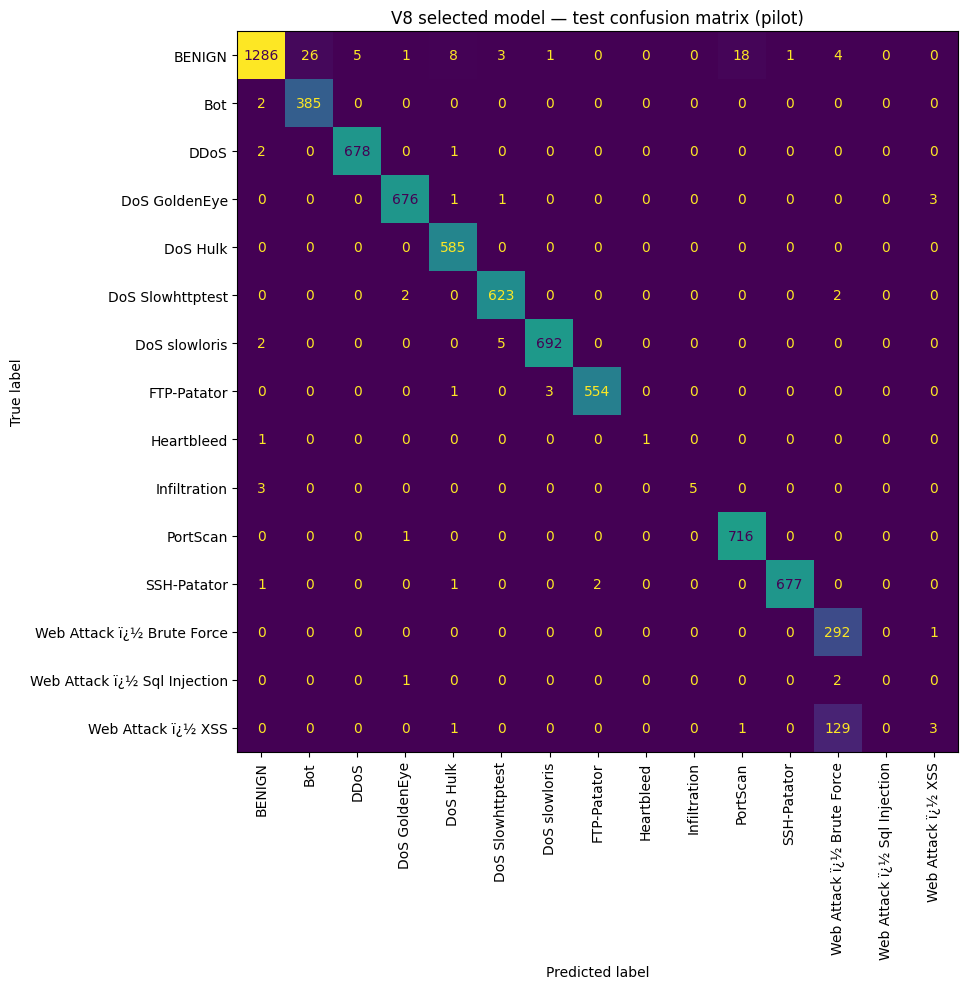

Worst test class F1:


,precision,recall,f1-score,support
Web Attack ï¿½ Sql Injection,0.000000,0.000000,0.000000,3.0
Web Attack ï¿½ XSS,0.428571,0.022388,0.042553,134.0
Heartbleed,1.000000,0.500000,0.666667,2.0
Infiltration,1.000000,0.625000,0.769231,8.0
Web Attack ï¿½ Brute Force,0.680653,0.996587,0.808864,293.0
Bot,0.936740,0.994832,0.964912,387.0
BENIGN,0.991519,0.950480,0.970566,1353.0
PortScan,0.974150,0.998605,0.986226,717.0


In [26]:
test_logits=restore_logits(selected_trial,'test')
test_pred=pred_with_bias(test_logits,float(selection['bias']))
test_metrics=performance(y['test'],test_pred)
final={
 'model':selected_trial['arch'],'selected_trial':int(selection['trial_id']),
 'selected_seed':int(selection['seed']),'bias':float(selection['bias']),
 'validation_macro_f1':float(selection['macro_f1']),
 'test':test_metrics,'feature_variant':feature_variant,'n_features':N_FEATURES,
 'n_classes':K,'test_n':len(y['test']),'split_sha256':sha,
 'note':'Pilot only. Prior test inspection makes this NOT a pristine independent test.'}
(OUTPUT/'final_test_metrics.json').write_text(json.dumps(final,ensure_ascii=False,indent=2))
print(json.dumps(final,ensure_ascii=False,indent=2))
test_report=classification_report(y['test'],test_pred,labels=all_ids,target_names=classes,
                                  output_dict=True,zero_division=0)
pd.DataFrame(test_report).T.to_csv(OUTPUT/'test_classification_report.csv')
cm=confusion_matrix(y['test'],test_pred,labels=all_ids)
np.save(OUTPUT/'test_confusion_matrix.npy',cm)
test_df=pd.DataFrame({'true_label':enc.inverse_transform(y['test']),
                      'pred_label':enc.inverse_transform(test_pred),
                      'source_file':df.loc[mask['test'],'_source_file'].to_numpy(),
                      'source_row':df.loc[mask['test'],'_source_row'].to_numpy()})
test_df.to_csv(OUTPUT/'test_predictions.csv',index=False)
test_wrong=test_df[test_df.true_label.ne(test_df.pred_label)]
test_wrong.groupby(['true_label','pred_label']).size().reset_index(name='count').sort_values('count',ascending=False).to_csv(OUTPUT/'test_confusion_pairs.csv',index=False)
shutil.copyfile(selected_trial['checkpoint'],OUTPUT/'selected_best.pt')
fig,ax=plt.subplots(figsize=(12,10))
ConfusionMatrixDisplay(cm,display_labels=classes).plot(ax=ax,xticks_rotation=90,colorbar=False)
ax.set_title('V8 selected model — test confusion matrix (pilot)');plt.tight_layout()
fig.savefig(OUTPUT/'test_confusion_matrix.png',dpi=140);plt.show()
print('Worst test class F1:')
display(pd.DataFrame(test_report).T.loc[classes].sort_values('f1-score').head(8))

## 11. Tổng hợp artifact, protocol và so sánh công bằng

In [27]:
manifest_out={
 'experiment':'05_CNN_Ablation_V8_Tokenized','input_path':str(split_path),
 'split_sha256':sha,'source_manifest':manifest,'feature_variant':feature_variant,
 'n_features':N_FEATURES,'features':features,'n_classes':K,
 'search_mode':SEARCH_MODE,'budget':BUDGET,'architectures':ARCHS,
 'selection_rule':'best validation 15-class Macro-F1; val-only BENIGN bias',
 'selected_trial':selection,
 'limitations':['No host/time/session-disjoint evaluation','CNN feature sequence has arbitrary adjacency',
                'Extremely rare attack classes','Test previously inspected in prior notebooks',
                'V8 is feature-attention not temporal-attention']}
(OUTPUT/'experiment_manifest.json').write_text(json.dumps(manifest_out,ensure_ascii=False,indent=2,default=str))
print('Saved files:',len([p for p in OUTPUT.rglob('*') if p.is_file()]))
print('Output folder:',OUTPUT)
print('04 V2 LightGBM reference on same 03B split: Accuracy 97.85%, Macro-F1 90.64%.')
print('For formal comparison, attach 04 V2 artifacts and verify the same split SHA256.')
print('Do not claim model improvement based only on previously viewed pilot test.')

Saved files: 73
Output folder: /kaggle/working/nids_outputs/05_CNN_Ablation_V8_Tokenized
04 V2 LightGBM reference on same 03B split: Accuracy 97.85%, Macro-F1 90.64%.
For formal comparison, attach 04 V2 artifacts and verify the same split SHA256.
Do not claim model improvement based only on previously viewed pilot test.
